# SASRec 

Ноутбук берёт обученный чекпойнт SASRec, восстанавливает архитектуру из `model_state`,подгружает EMA-веса и считает full-rank метрики HR@K / NDCG@K на валидации и тесте.Протокол оценки тот же, что в обучении (`src/evaluate.py`): ранжирование по всему каталогуиз 11924 товаров, без sampled negatives.

In [61]:
import sys, os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
sys.path.append('../src')

import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt

from models.sasrec import SASRec
from data import build_dataloaders
from evaluate import evaluate

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

In [62]:
# ════════════════════════════════════════════════════════════
# КОНФИГ
# ════════════════════════════════════════════════════════════
CKPT_DIR    = '../checkpoints/sasrec_baseline'   # какой ран оцениваем
CKPT_NAME   = 'best.pt'                          # 'best.pt' или 'latest.pt'
CONFIG_PATH = '../configs/sasrec.yaml'           # нужен только для n_heads / loss / temperature
DATA_DIR    = '../data/ATG'

N_ITEMS    = 11924
PADDING    = 11924
BATCH_SIZE = 512
TOP_K      = (5, 10, 20)
USE_EMA    = True    # оценивать EMA-веса (так же, как во время обучения)
SEED       = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


1. Загрузка чекпойнта и модели`save_checkpoint` в `train_sasrec.py` не кладёт гиперпараметры модели, поэтому размеры(`d_model`, `n_layers`, `d_ff`, `max_seq_len`, `tie_weights`) восстанавливаем из `model_state`,а то, что в весах не отражено (`n_heads`, тип лосса, температура) — берём из YAML-конфига.Тип лосса важен: при `infonce` скоринг в `recommend()` косинусный, при `ce` — скалярное произведение.

In [63]:
ckpt_path = Path(CKPT_DIR) / CKPT_NAME
if not ckpt_path.exists():
    ckpt_path = Path(CKPT_DIR) / 'latest.pt'
print(f'Checkpoint: {ckpt_path}')

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
sd   = ckpt['model_state']
print(f'epoch = {ckpt.get("epoch")}, step = {ckpt.get("step")}')
print(f'metrics в чекпойнте: {ckpt.get("metrics")}')

# ── Размеры из state_dict ────────────────────────────────────
d_model     = sd['item_embedding.weight'].shape[1]
n_items_ck  = sd['item_embedding.weight'].shape[0] - 1     # последняя строка — padding
max_seq_len = sd['pos_embedding.weight'].shape[0]
n_layers    = len({k.split('.')[1] for k in sd if k.startswith('blocks.')})
d_ff        = sd['blocks.0.ff.0.weight'].shape[0]
tie_weights = 'output_proj.weight' not in sd

assert n_items_ck == N_ITEMS, f'n_items в чекпойнте {n_items_ck} != {N_ITEMS}'

# ── Остальное из YAML ────────────────────────────────────────
raw = yaml.safe_load(open(CONFIG_PATH))
m   = raw.get('model', {})
n_heads     = int(m.get('n_heads', 4))
loss_type   = str(m.get('loss', 'infonce'))
temperature = float(m.get('temperature', 0.07))

print(f'\nd_model={d_model}, n_heads={n_heads}, n_layers={n_layers}, d_ff={d_ff}, '
      f'max_seq_len={max_seq_len}, tie_weights={tie_weights}, loss={loss_type}')

Checkpoint: ..\checkpoints\sasrec_baseline\best.pt
epoch = 90, step = 5400
metrics в чекпойнте: {'HR@10': 0.047398246824741364, 'NDCG@10': 0.03100994974374771, 'HR@20': 0.061308603733778, 'NDCG@20': 0.034494467079639435}

d_model=128, n_heads=1, n_layers=1, d_ff=128, max_seq_len=10, tie_weights=True, loss=infonce


In [64]:
model = SASRec(
    n_items=N_ITEMS,
    padding_idx=PADDING,
    d_model=d_model,
    n_heads=n_heads,
    n_layers=n_layers,
    d_ff=d_ff,
    dropout=0.0,               # eval-режим, dropout не участвует
    max_seq_len=max_seq_len,
    tie_weights=tie_weights,
    loss=loss_type,
    temperature=temperature,
).to(device)
model.load_state_dict(sd)

ema_shadow = ckpt.get('ema_shadow', {})
if USE_EMA and ema_shadow:
    missing = [n for n, _ in model.named_parameters() if n not in ema_shadow]
    for name, param in model.named_parameters():
        if name in ema_shadow:
            param.data.copy_(ema_shadow[name].to(device))
    print(f'EMA-веса загружены (без EMA осталось параметров: {len(missing)})')
else:
    print('Оцениваем raw-веса (без EMA)')

model.eval()
print(f'Trainable params: {model.param_summary()["total_trainable"]:,}')

EMA-веса загружены (без EMA осталось параметров: 0)
Trainable params: 1,627,520


## 2. Данные

In [65]:
loaders = build_dataloaders(
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    num_workers=0,             # в ноутбуке на Windows воркеры не нужны
    seq_len=max_seq_len,
    splits=('val', 'test'),
)
for name, loader in loaders.items():
    print(f'{name:5s}: {len(loader.dataset):,} sequences')

val  : 1,941 sequences
test : 1,942 sequences


3. Метрики на val и test 
Full-rank: для каждой истории берём top-20 товаров по всему каталогу и считаемHR@K (доля историй, где таргет попал в top-K) и NDCG@K (1/log2(rank+1) при попадании).

In [66]:
results = {}
for split in ('val', 'test'):
    torch.manual_seed(SEED)
    results[split] = evaluate(
        model=model,
        dataloader=loaders[split],
        top_k_values=TOP_K,
        num_sample_steps=1,     # SASRec не сэмплирует, аргумент для совместимости
        w_cfg=0.0,              # то же
        device=device,
        show_progress=True,
    )
    print(f'{split}: ' + '  '.join(f'{k}={v:.4f}' for k, v in results[split].items()))

metrics_df = pd.DataFrame(results).T.round(4)
metrics_df.index.name = 'split'
metrics_df

val: HR@5=0.0350  NDCG@5=0.0271  HR@10=0.0474  NDCG@10=0.0310  HR@20=0.0613  NDCG@20=0.0345


test: HR@5=0.0350  NDCG@5=0.0246  HR@10=0.0479  NDCG@10=0.0288  HR@20=0.0685  NDCG@20=0.0339


,HR@5,NDCG@5,HR@10,NDCG@10,HR@20,NDCG@20
split,,,,,,
val,0.035,0.0271,0.0474,0.0310,0.0613,0.0345
test,0.035,0.0246,0.0479,0.0288,0.0685,0.0339


## 4. Сравнение со случайным ранжированиемАналитический baseline: HR@K = K / N_items, NDCG@K = (Σ_{r<K} 1/log2(r+2)) / N_items.Показывает, во сколько раз модель лучше случая (lift).

In [67]:
def analytical_random(k, n_items=N_ITEMS):
    hr   = k / n_items
    nd   = sum(1.0 / np.log2(r + 2) for r in range(k)) / n_items
    return hr, nd


rows = []
for split in ('val', 'test'):
    for k in TOP_K:
        hr_rnd, nd_rnd = analytical_random(k)
        hr, nd = results[split][f'HR@{k}'], results[split][f'NDCG@{k}']
        rows.append({
            'split': split, 'K': k,
            'HR': round(hr, 4), 'HR random': round(hr_rnd, 5), 'HR lift': round(hr / hr_rnd, 1),
            'NDCG': round(nd, 4), 'NDCG random': round(nd_rnd, 5), 'NDCG lift': round(nd / nd_rnd, 1),
        })

comparison = pd.DataFrame(rows).set_index(['split', 'K'])
comparison

HR  HR random  HR lift    NDCG  NDCG random  NDCG lift
split K                                                             
val   5   0.0350    0.00042     83.5  0.0271      0.00025      109.6
      10  0.0474    0.00084     56.5  0.0310      0.00038       81.4
      20  0.0613    0.00168     36.6  0.0345      0.00059       58.4
test  5   0.0350    0.00042     83.5  0.0246      0.00025       99.6
      10  0.0479    0.00084     57.1  0.0288      0.00038       75.5
      20  0.0685    0.00168     40.8  0.0339      0.00059       57.4

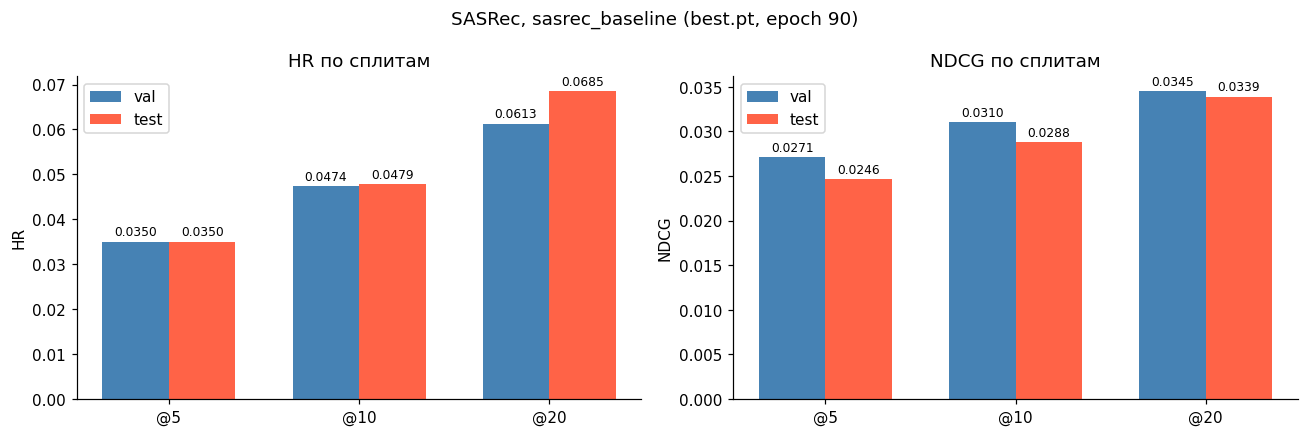

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(TOP_K))
width = 0.35

for ax, metric in zip(axes, ['HR', 'NDCG']):
    for i, (split, color) in enumerate([('val', 'steelblue'), ('test', 'tomato')]):
        vals = [results[split][f'{metric}@{k}'] for k in TOP_K]
        bars = ax.bar(x + (i - 0.5) * width, vals, width, label=split, color=color)
        ax.bar_label(bars, fmt='%.4f', fontsize=8, padding=2)
    ax.set_xticks(x, [f'@{k}' for k in TOP_K])
    ax.set_ylabel(metric)
    ax.set_title(f'{metric} по сплитам')
    ax.legend()

fig.suptitle(f'SASRec, {Path(CKPT_DIR).name} ({ckpt_path.name}, epoch {ckpt.get("epoch")})')
fig.tight_layout()
plt.show()

## 5. Кривые обучения`log_train.csv` — лосс по эпохам, `log_val.csv` — val-лосс и метрики каждые `eval_every_epochs`эпох (последняя строка с `epoch == 'test'` — финальный тест из обучения, её отбрасываем).

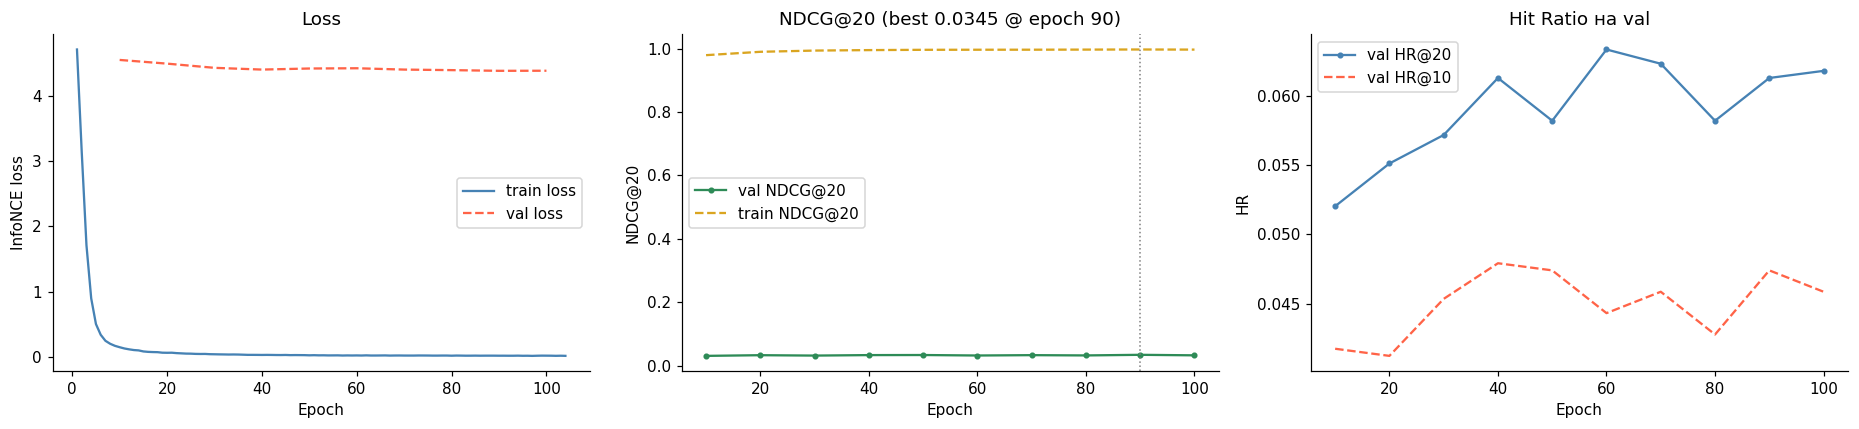

In [69]:
train_log_path = Path(CKPT_DIR) / 'log_train.csv'
val_log_path   = Path(CKPT_DIR) / 'log_val.csv'

train_log = pd.read_csv(train_log_path) if train_log_path.exists() else None
val_log   = pd.read_csv(val_log_path)   if val_log_path.exists()   else None

if val_log is not None:
    # Строка 'test' в конце лога — не эпоха, убираем
    val_log = val_log[pd.to_numeric(val_log['epoch'], errors='coerce').notna()].copy()
    val_log['epoch'] = val_log['epoch'].astype(int)
    for col in ('val_loss', 'train_ndcg20', 'NDCG@20', 'HR@20'):
        if col in val_log:
            val_log[col] = pd.to_numeric(val_log[col], errors='coerce')

if train_log is None and val_log is None:
    print(f'Логи не найдены в {CKPT_DIR}')
else:
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))

    ax = axes[0]
    if train_log is not None:
        ax.plot(train_log['epoch'], train_log['loss'], color='steelblue', lw=1.5, label='train loss')
    if val_log is not None and 'val_loss' in val_log:
        ax.plot(val_log['epoch'], val_log['val_loss'], color='tomato', lw=1.5, ls='--', label='val loss')
    ax.set_xlabel('Epoch'); ax.set_ylabel('InfoNCE loss' if loss_type == 'infonce' else 'CE loss')
    ax.set_title('Loss'); ax.legend()

    ax = axes[1]
    if val_log is not None:
        ax.plot(val_log['epoch'], val_log['NDCG@20'], color='seagreen', lw=1.5, marker='o',
                ms=3, label='val NDCG@20')
        if 'train_ndcg20' in val_log:
            ax.plot(val_log['epoch'], val_log['train_ndcg20'], color='goldenrod', lw=1.5,
                    ls='--', label='train NDCG@20')
        best_row = val_log.loc[val_log['NDCG@20'].idxmax()]
        ax.axvline(best_row['epoch'], color='grey', ls=':', lw=1)
        ax.set_title(f'NDCG@20 (best {best_row["NDCG@20"]:.4f} @ epoch {int(best_row["epoch"])})')
    ax.set_xlabel('Epoch'); ax.set_ylabel('NDCG@20'); ax.legend()

    ax = axes[2]
    if val_log is not None:
        ax.plot(val_log['epoch'], val_log['HR@20'], color='steelblue', lw=1.5, marker='o',
                ms=3, label='val HR@20')
        if 'HR@10' in val_log:
            ax.plot(val_log['epoch'], pd.to_numeric(val_log['HR@10'], errors='coerce'),
                    color='tomato', lw=1.5, ls='--', label='val HR@10')
    ax.set_xlabel('Epoch'); ax.set_ylabel('HR'); ax.set_title('Hit Ratio на val'); ax.legend()

    fig.tight_layout()
    plt.show()

## 6. Итог

In [ ]:
summary = pd.DataFrame({
    'run':        [Path(CKPT_DIR).name],
    'checkpoint': [ckpt_path.name],
    'epoch':      [ckpt.get('epoch')],
    'EMA':        [bool(USE_EMA and ema_shadow)],
    **{f'val {k}':  [round(results['val'][k], 4)]  for k in results['val']},
    **{f'test {k}': [round(results['test'][k], 4)] for k in results['test']},
}).set_index('run')

print(f'SASRec / ATG, чекпойнт {ckpt_path}')
summary.T

SASRec / ATG, чекпойнт ..\checkpoints\sasrec_baseline\best.pt


run,sasrec_baseline
checkpoint,best.pt
epoch,90
EMA,True
val HR@5,0.035
val NDCG@5,0.0271
val HR@10,0.0474
val NDCG@10,0.031
val HR@20,0.0613
val NDCG@20,0.0345
test HR@5,0.035


: 